### Evaluation metrics deep dive
## objectives.
- Choosing the right
- Interpreting rmse and r-squared for regression models.
- Precision recall.


## Classification metrics.
-> Accuracy = (TP + TN)/TOTAL where : tp = true postives : tn = true negatives

When to use accuracy -> When classes are balanced.
EG. When not to use accuracy, if 95% of emails are not spam, a model that
predicts 'not spam' alwayd gets 95% accuracy - but is useless.

-> precision = TP/(TP + FP) where fp = false positives

Out of everything the model predicted as postive, how many were actually correct?
- When to use: When false alarms are costly, eg in a spam filter, when real emails are marked as spam
or in fraud detection when legitimate users are blocked.

-> Recall = TP/ (TP + FN). Focus: False Negatives.
Out of all actual postives, how many did we catch.
- When to use: When missing a postive case is dangerous.
examples: In cancer detection, don't miss sick patients, In security threats, don't miss attacks.
``` recall = ability to find all positives ```

F1 score = Harmonic mean of precision and recall, penalizes the imbalance of precision and recall.
``` 2 * (p * r)/ (p + r) ```
When to use:
- Need a single metric.
- Classes are imbalanced.
- Precision and recall are equally important.



In [1]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()

X,y=data.data, data.target


In [2]:
## spliting the data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [3]:
# scaling data
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test =sc.transform(X_test)

In [4]:
## Train a logistic regression model
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000).fit(X_train, y_train)
y_prob = model.predict_proba(X_test)[:, 1]



In [5]:
model.predict_proba(X_test)

array([[1.13590250e-01, 8.86409750e-01],
       [9.99990991e-01, 9.00936206e-06],
       [9.96920905e-01, 3.07909541e-03],
       [5.10134225e-04, 9.99489866e-01],
       [6.06389713e-05, 9.99939361e-01],
       [1.00000000e+00, 9.48087773e-11],
       [9.99999998e-01, 1.53672648e-09],
       [9.65096937e-01, 3.49030633e-02],
       [3.79342140e-01, 6.20657860e-01],
       [7.59402734e-04, 9.99240597e-01],
       [4.98717826e-02, 9.50128217e-01],
       [9.87592879e-01, 1.24071210e-02],
       [6.07381873e-03, 9.93926181e-01],
       [8.56069117e-01, 1.43930883e-01],
       [1.62175599e-03, 9.98378244e-01],
       [9.99259818e-01, 7.40182295e-04],
       [1.85245908e-03, 9.98147541e-01],
       [1.11662359e-05, 9.99988834e-01],
       [8.18375684e-07, 9.99999182e-01],
       [9.99998883e-01, 1.11701472e-06],
       [8.41633901e-02, 9.15836610e-01],
       [9.74778299e-03, 9.90252217e-01],
       [9.99999996e-01, 4.33732393e-09],
       [7.89186669e-05, 9.99921081e-01],
       [1.138743

In [6]:
y_pred = (y_prob >= 0.5).astype(int)
y_pred

array([1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1,
       0, 1, 0, 0])

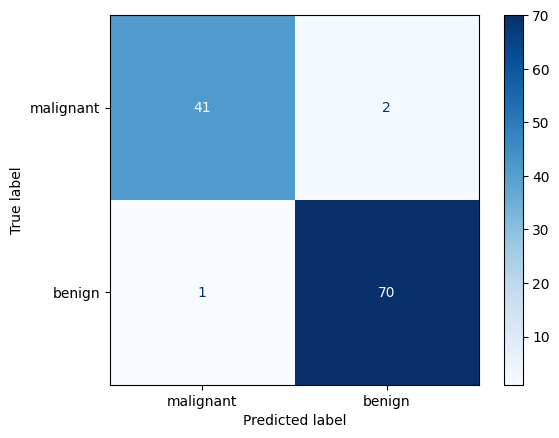

In [7]:
from sklearn.metrics import(classification_report, confusion_matrix, ConfusionMatrixDisplay)

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data.target_names).plot(cmap='Blues')


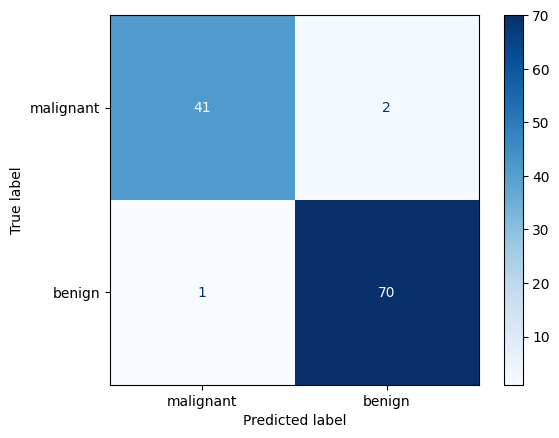

In [8]:
import matplotlib.pyplot as plt
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test,display_labels=data.target_names,cmap='Blues')
plt.show()

In [9]:
print(classification_report(y_test, y_pred, target_names=data.target_names))

              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        43
      benign       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



## Regression metrics - deep dive
## 1. MAE (Mean Absolute Error)

- Average abdolute difference between predictions and actual values.

``` 1/n Σ|y_true -  y_pred| ```

- Treats all errors equally.
- No squaring, no extra punishment for large errors.

Question we are trying to answer: On average, by how many units are we off?

### Example:
If predicting house prices:
- MAE = 10000, average error is 10k

### 2. MSE(Mean Squared Error)
Average squared error

```(Σ(y_true - y_pred) ^2) / n```
- Large errors get penalized more.
- Emphasize on bad mistakes.

- Harder to interpret directly.

### 2. RMSE (Root Mean Squared Error)
Same MSE, but converted back to original units.

```python
   import numpy as np 
   np.sqrt(MSE) 
```

Why is rmse used a lot?
- Keeps penalty for large errors.
- Still interpretable.

### 4.  R^2 (R-squared)
How much better is the model compared to just predicting the mean?
- 1.0 -> Perfect predictions.
- 0.0 -> Same as predicting the mean.
- < 0 -> Worse thsn predicting the mean.

``` SSres = Σ(y_true - y_pred)^2 ```
``` SStot = Σ(y_true - y_mean)^2 ```
``` R^2 = 1 - (SSres/SStot) ```
USE WHEN: 
- Comparing models.
- Explaining variance captured.

In [10]:
# Loading Data
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(diabetes.data, diabetes.target,test_size=0.2,random_state=42)

In [12]:
diabetes.target

array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
        69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
        68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
        87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
       259.,  53., 190., 142.,  75., 142., 155., 225.,  59., 104., 182.,
       128.,  52.,  37., 170., 170.,  61., 144.,  52., 128.,  71., 163.,
       150.,  97., 160., 178.,  48., 270., 202., 111.,  85.,  42., 170.,
       200., 252., 113., 143.,  51.,  52., 210.,  65., 141.,  55., 134.,
        42., 111.,  98., 164.,  48.,  96.,  90., 162., 150., 279.,  92.,
        83., 128., 102., 302., 198.,  95.,  53., 134., 144., 232.,  81.,
       104.,  59., 246., 297., 258., 229., 275., 281., 179., 200., 200.,
       173., 180.,  84., 121., 161.,  99., 109., 115., 268., 274., 158.,
       107.,  83., 103., 272.,  85., 280., 336., 281., 118., 317., 235.,
        60., 174., 259., 178., 128.,  96., 126., 28

In [13]:
# Training the model
from statistics import LinearRegression

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [14]:
y_pred = model.predict(X_test)


In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mae

42.79409467959994

In [16]:
import numpy as np

mse =mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(f'rmse: {rmse}, mse: {mse}')

rmse: 53.85344583676592, mse: 2900.1936284934804


In [17]:
r2 = r2_score(y_test,  y_pred)
r2


0.4526027629719197

# Learning curves: Diagnosing Overfitting and underfitting.
- A learning curve shows how training and validation performance change as we increase the amount of traing data.

Overfitting -> More data, regularization , simpler model.
Underfitting -> More complex model, Add more features, less regularization.


In [23]:
from sklearn.model_selection import learning_curve


def plot_learning_curve(model, X,y, title = 'Learning Curve'):
    train_sizes, train_scores, val_scores = learning_curve(
        model,X, y,
        cv = 5, # the no. of folds it splits our data into 5 parts 
        train_sizes = np.linspace(0.1, 1.0, 10),
        n_jobs = -1
    )

    train_mean = train_scores.mean(axis = 1)
    train_std = train_scores.std(axis = 1)

    val_mean = val_scores.mean(axis = 1)
    val_std = val_scores.std(axis = 1)

    plt.figure(figsize=(10,6))
    
    plt.plot(train_sizes, train_mean, 'o', label='Training score')
    plt.plot(train_sizes, val_mean, 's', label='Validation score' ) 

    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.3)
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.3)
    plt.legend()
    plt.show()






In [19]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()


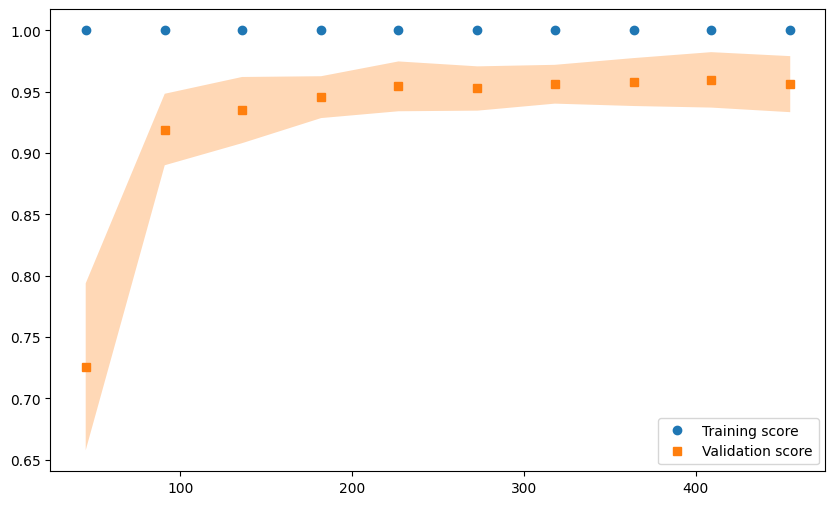

In [22]:
from sklearn.ensemble import RandomForestClassifier

plot_learning_curve(RandomForestClassifier(random_state=42), data.data, data.target,
                    'Learning curve - Random Forest')